# K-Means Clustering

### What does K-Means do?


It partitions `n` data points into `k` groups `(clusters)` such that points within a cluster are as similar as possible

**The core idea in 3 steps (the "Lloyd's algorithm")**

* **Assign** each piont to the nearest centroid
* **Update** each centroid to be the mean of the points assigned to it
* **Repeat** steps 1-2 until centroids stop moving (convergence)

**Key Parameters:**
* `k`&rarr; number of clusters (must choose this; it's the main limitation)
* `max_iter`&rarr; safety cap on how many loops we run
* `tol`&rarr; toleracne; if centroids move less than this, we stop early ("converged")

**The Building Blocks (Functions)**

|**Functions**|**Purpose**|
|-------------|-----------|
|`init_centroids(X,k)`|Pick starting centroids|
|`assign_clusters(X,centroids)`|For each point, find nearest centroid&rarr; labels|
|`update_centroids(X,labels,k)`|Recompute each centroid as mean of its cluster|
|`kmeans(X,k,max_iter,tol)`|Orchestrates the loop|


##### Set Up

In [17]:
import numpy as np

# 2D points - easy to visualize
X = np.array([
    [1, 2],
    [1, 3],
    [2, 2],
    [8, 8],
    [9, 8],
    [8, 9],
])

X.shape

(6, 2)

`X` has shpea `(6,2)`- 6 points, 2 features

**Function 1: `init_centroids`**

In [18]:
def init_centroids(X,k,seed = 42):
  rng = np.random.default_rng(seed) # reproducible ranfomness
  idx = rng.choice(len(X), size = k, replace = False) # pick k distinct piont indices
  return X[idx].copy() # return those rows as starting centroids

**Function 2: `assign_clusters`**

In [19]:
def assign_clusters(X, centroids):
  # For each point, compute distance to each centroid
  diffs = X[:,np.newaxis,:] - centroids[np.newaxis,:,:] # diffs = shape(n,k,2)
  dists = np.sqrt(diffs**2).sum(axis = 2)

  return dists.argmin(axis = 1)


**Function 3: `update_centroids`**

In [20]:
def update_centroids(X,labels,k):
  new_centroids = np.zeros((k,X.shape[1]))
  for i in range(k):
    members = X[labels == i]

    if len(members > 0):
      new_centroids[i] = members.mean(axis = 0)
  return new_centroids

**Function 4: `kmeans` (orchestrator)**

In [29]:
def compute_inertia(X, labels, centroids):
    diffs = X - centroids[labels]
    return np.sum(diffs ** 2)

def kmeans(X, k, max_iters=100, tol=1e-4, seed=42):
    centroids = init_centroids(X, k, seed)
    for it in range(max_iters):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, k)
        shift = np.linalg.norm(new_centroids - centroids)
        centroids = new_centroids
        if shift < tol:
            break
    labels = assign_clusters(X, centroids)          # ← consistency fix
    inertia = compute_inertia(X, labels, centroids) # ← final score
    return centroids, labels, inertia

**Run It**

In [30]:
centroids, labels, inertia = kmeans(X, k=2, max_iters = 100)
print("Centroids:\n", centroids.round(2))
print("Labels:", labels)
print(f"Final inertia: {inertia:.4f}")

Centroids:
 [[1.33 2.33]
 [8.33 8.33]]
Labels: [0 0 0 1 1 1]
Final inertia: 2.6667


In [27]:
def inertia(X,labels,centroids):
  return sum(np.sum((X[labels == i] - centroids[i])**2) for i in range(centroids))

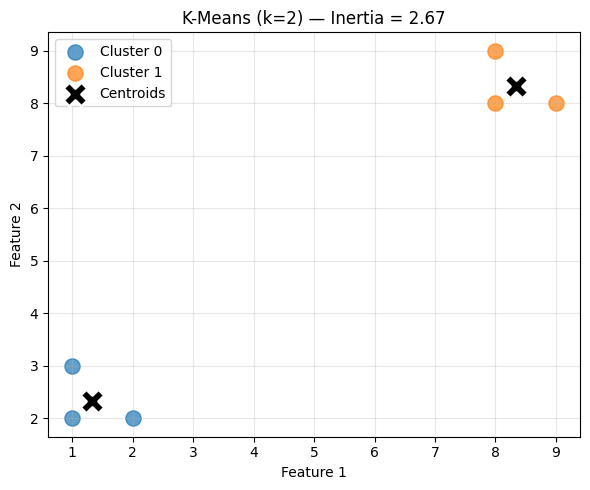

In [31]:
import matplotlib.pyplot as plt

# --- our tiny dataset from before ---
X = np.array([
    [1, 2], [1, 3], [2, 2],
    [8, 8], [9, 8], [8, 9],
])

# --- run kmeans (returns centroids, labels, inertia) ---
centroids, labels, inertia = kmeans(X, k=2)

# --- build the plot ---
fig, ax = plt.subplots(figsize=(6, 5))

# 1. scatter each cluster in its own color
for i in range(len(centroids)):
    pts = X[labels == i]                                  # rows belonging to cluster i
    ax.scatter(pts[:, 0], pts[:, 1], s=120, label=f'Cluster {i}', alpha=0.7)

# 2. overlay centroids
ax.scatter(centroids[:, 0], centroids[:, 1],
           s=300, marker='X', c='black', edgecolors='white',
           linewidths=2, label='Centroids', zorder=5)

# 3. cosmetics
ax.set_title(f'K-Means (k=2) — Inertia = {inertia:.2f}')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Elbow Method**

In [32]:
import numpy as np
import matplotlib.pyplot as plt

def elbow_plot(X, k_max=6, seed=42, verbose=True):
    ks = list(range(1, k_max + 1))
    inertias = []
    for k in ks:
        _, _, inertia = kmeans(X, k, seed=seed)
        inertias.append(inertia)
        if verbose:
            print(f"k={k}: inertia={inertia:.3f}")
    # plot
    plt.figure(figsize=(7, 4.5))
    plt.plot(ks, inertias, 'o-', color='steelblue', markersize=9, linewidth=2)
    plt.xlabel('k (number of clusters)')
    plt.ylabel('Inertia (sum of squared distances)')
    plt.title('Elbow Method')
    plt.xticks(ks)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return ks, inertias

k=1: inertia=130.167
k=2: inertia=2.667
k=3: inertia=1.833
k=4: inertia=1.000
k=5: inertia=0.500
k=6: inertia=0.000


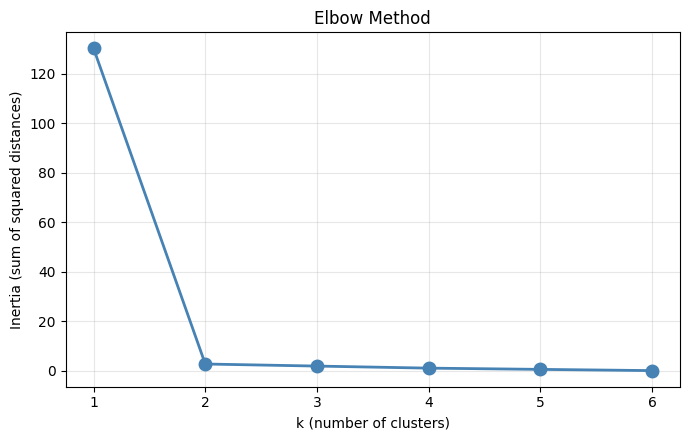

In [33]:
ks, inertias = elbow_plot(X, k_max=6)